# Reserve resources with a placement group

A placement group reserves two one-CPU bundles. Each task is pinned to a bundle, and the group is removed at the end.

**When to use it.** Gang scheduling: work that only makes sense when all its pieces get resources together, or that must be packed onto (or spread across) nodes.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

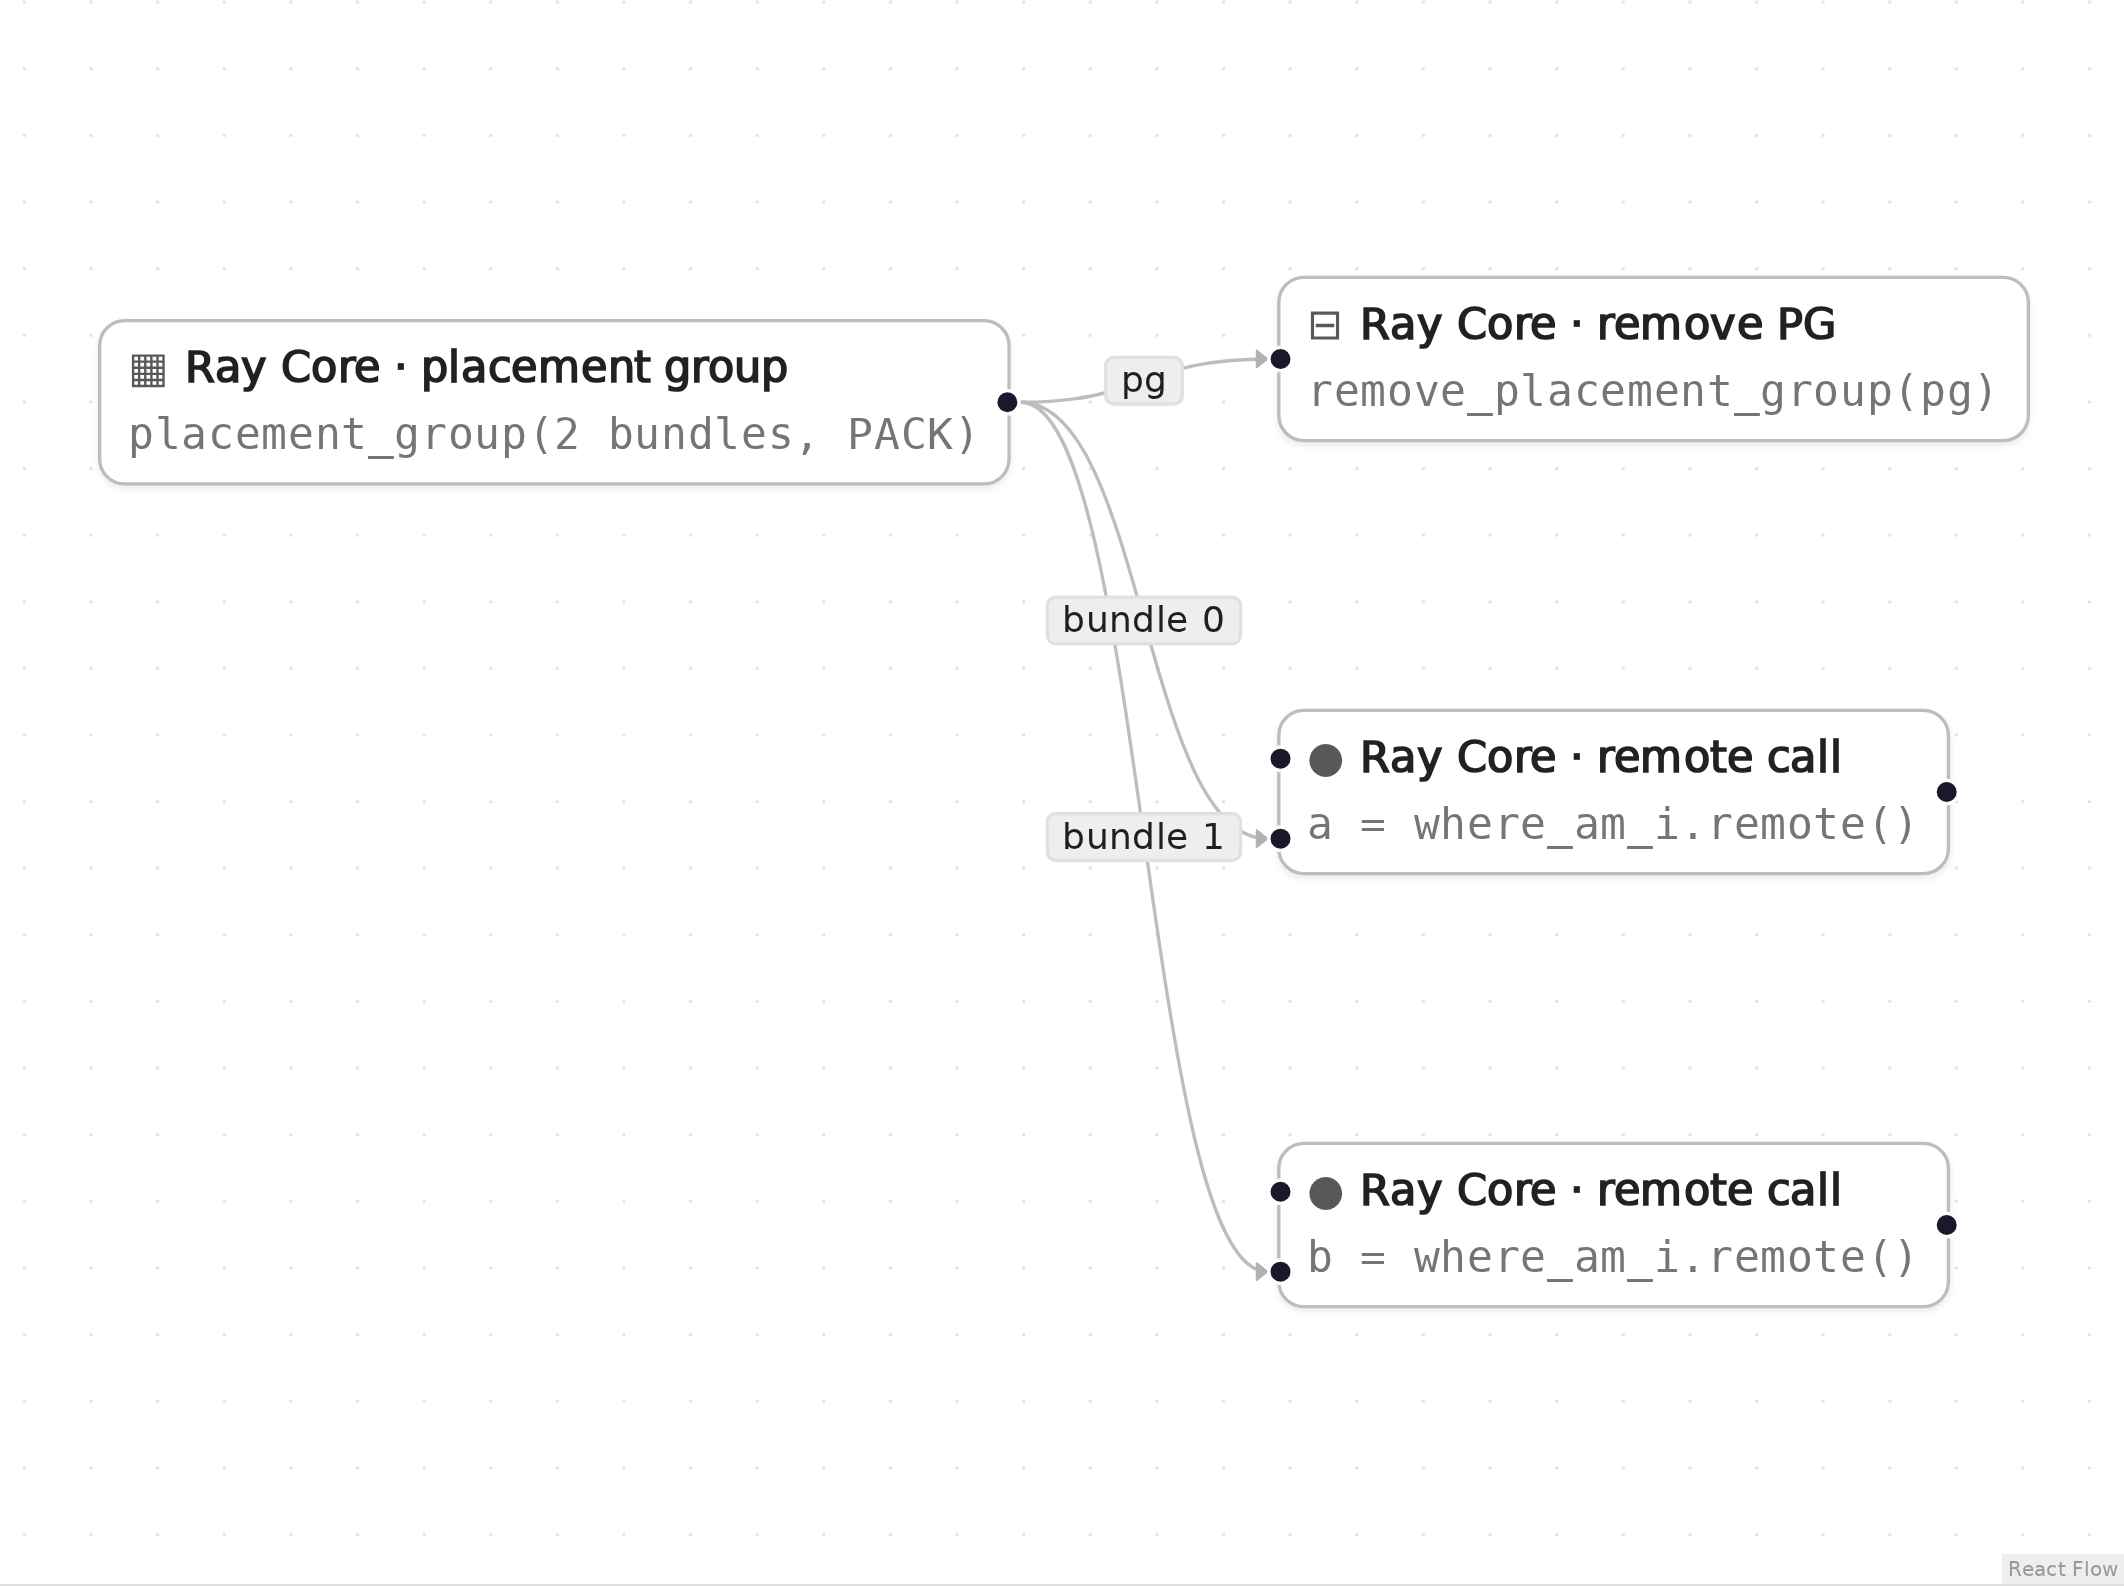

*The graph in Eugo's visual Ray builder.* `a` (node `n1`) runs in bundle 0 and `b` (node `n2`) in bundle 1. The *bundle 1* label belongs to the longer edge that goes to `b`, although it sits next to the input of `a`.

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
import ray


def where_am_i(tag):
    pg_id = ray.get_runtime_context().get_placement_group_id()
    return f"{tag} ran in placement group {pg_id[:8]}"

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray
from ray.util.placement_group import placement_group, remove_placement_group
from ray.util.scheduling_strategies import PlacementGroupSchedulingStrategy

if not ray.is_initialized():
    ray.init()

_pg_pg1 = placement_group(bundles=[{"CPU": 1}, {"CPU": 1}], strategy="PACK")
ray.get(_pg_pg1.ready())
_n1 = ray.remote(where_am_i).options(scheduling_strategy=PlacementGroupSchedulingStrategy(placement_group=_pg_pg1, placement_group_bundle_index=0)).remote("task-0")
a = ray.get(_n1)
_n2 = ray.remote(where_am_i).options(scheduling_strategy=PlacementGroupSchedulingStrategy(placement_group=_pg_pg1, placement_group_bundle_index=1)).remote("task-1")
b = ray.get(_n2)
remove_placement_group(_pg_pg1)

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
import time

from ray.util import placement_group_table

assert a.startswith("task-0 ran in placement group"), a
assert b.startswith("task-1 ran in placement group"), b
for _ in range(100):
    if placement_group_table(_pg_pg1)["state"] == "REMOVED":
        break
    time.sleep(0.1)
else:
    raise AssertionError(placement_group_table(_pg_pg1)["state"])
print(a)
print(b)

task-0 ran in placement group 9d189e85
task-1 ran in placement group 9d189e85


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–5 and 7–8)

```python
# Generated with Eugo's visual Ray builder
...
import ray
from ray.util.placement_group import placement_group, remove_placement_group
from ray.util.scheduling_strategies import PlacementGroupSchedulingStrategy
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Placement group** (node `pg1`, lines 10–11)

```python
_pg_pg1 = placement_group(bundles=[{"CPU": 1}, {"CPU": 1}], strategy="PACK")
ray.get(_pg_pg1.ready())
```

placement_group reserves two bundles of one CPU each with the PACK strategy (as few nodes as possible); ray.get(pg.ready()) waits until the reservation holds.

**Remote task** (node `n1`, lines 12–13)

```python
_n1 = ray.remote(where_am_i).options(scheduling_strategy=PlacementGroupSchedulingStrategy(placement_group=_pg_pg1, placement_group_bundle_index=0)).remote("task-0")
a = ray.get(_n1)
```

PlacementGroupSchedulingStrategy with placement_group_bundle_index=0 pins this task to the first bundle.

**Remote task** (node `n2`, lines 14–15)

```python
_n2 = ray.remote(where_am_i).options(scheduling_strategy=PlacementGroupSchedulingStrategy(placement_group=_pg_pg1, placement_group_bundle_index=1)).remote("task-1")
b = ray.get(_n2)
```

The second task is pinned to bundle 1.

**Remove PG** (node `r1`, line 16)

```python
remove_placement_group(_pg_pg1)
```

remove_placement_group releases the reserved resources.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()